# 🧪 Notebook 7 — Gillespie Minis: ATRP & Polymer Degradation
| | |
|---|---|
| ⏱ Time | ~25 min |
| 🎯 You will learn | reuse the Gillespie recipe for (A) **controlled** radical polymerization and (B) **breaking** polymers apart |
| 🧰 Uses | everything from Notebook 6 |
| 📖 Book algorithms | *Monte Carlo Algorithm for ATRP Copolymerization* · *Gillespie Algorithm for Polystyrene Thermal Degradation* |

These are deliberately **mini** versions (homopolymer ATRP; two-reaction degradation) with toy numbers, so the idea is clear. The full mechanisms (copolymer ATRP, 9-reaction PS pyrolysis) are in *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(9)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})

def take_random(lst):
    k = random.randrange(len(lst)); v = lst[k]; lst[k] = lst[-1]; lst.pop(); return v

def roulette(R):
    r, j, acc = random.random()*sum(R), 0, R[0]
    while acc < r: j += 1; acc += R[j]
    return j

## Part A · ATRP: chains that *sleep* most of the time 😴
In ATRP every chain starts at the same time and spends most of its life **dormant** (`P–X`). A copper catalyst wakes it up briefly:

| reaction | what happens |
|---|---|
| activation | `P–X + Cu(I) → P• + Cu(II)X` |
| deactivation | `P• + Cu(II)X → P–X + Cu(I)` |
| propagation | `P•ₙ + M → P•ₙ₊₁` |
| termination | `P• + P• → dead` |

Because all chains grow a little, then sleep, then grow again, they end up **almost the same length** → low Đ, and `Nn` grows **linearly** with conversion.

In [2]:
def atrp(nM0=20_000, nPX0=200, nCu1=180, nCu2=20, NAV=1e4,
         ka=111.0, kda=1e5, kp=100.0, kt=3e2, x_max=0.9):
    k = dict(ka=ka/NAV, kda=kda/NAV, kp=kp/NAV, kt=kt/NAV)    # all bimolecular
    dormant, active, dead = [0]*nPX0, [], []
    nM, t, step, hist = nM0, 0.0, 0, {"x": [], "Nn": [], "PDI": [], "Cu2": []}
    while (nM0 - nM)/nM0 < x_max:
        nP = len(active)
        R = [k["ka"]*len(dormant)*nCu1, k["kda"]*nP*nCu2, k["kp"]*nP*nM, k["kt"]*nP*(nP-1)]
        j = roulette(R)
        if j == 0:   active.append(take_random(dormant)); nCu1 -= 1; nCu2 += 1
        elif j == 1: dormant.append(take_random(active)); nCu1 += 1; nCu2 -= 1
        elif j == 2: active[random.randrange(nP)] += 1; nM -= 1
        else:        dead.append(take_random(active) + take_random(active))
        t += np.log(1/random.random()) / sum(R); step += 1
        if step % 500 == 0:
            L = np.array(dormant + active + dead)
            hist["x"].append((nM0-nM)/nM0); hist["Nn"].append(L.mean())
            hist["PDI"].append((L**2).mean()/L.mean()**2); hist["Cu2"].append(nCu2)
    return {k: np.array(v) for k, v in hist.items()}, np.array(dormant + active + dead), step

H, chains, steps = atrp()
print(f"{steps:,} events.  Final Đ = {H['PDI'][-1]:.3f}  (free-radical polymerization: ~1.5–2)")

158,376 events.  Final Đ = 1.039  (free-radical polymerization: ~1.5–2)


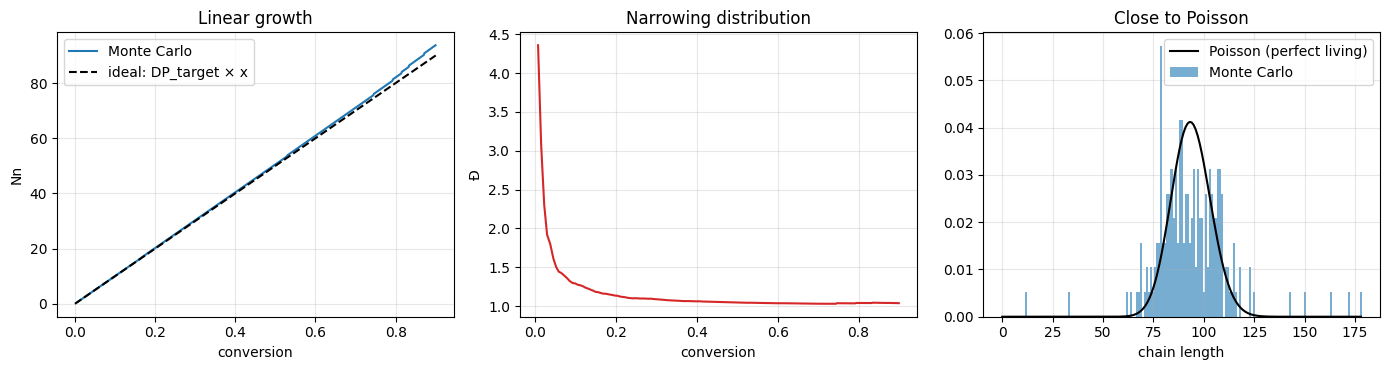

In [3]:
from scipy.stats import poisson
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(H["x"], H["Nn"], label="Monte Carlo"); ax[0].plot([0, 0.9], [0, 0.9*100], "k--", label="ideal: DP_target × x")
ax[0].set_xlabel("conversion"); ax[0].set_ylabel("Nn"); ax[0].legend(); ax[0].set_title("Linear growth")
ax[1].plot(H["x"], H["PDI"], c="tab:red"); ax[1].set_xlabel("conversion"); ax[1].set_ylabel("Đ"); ax[1].set_title("Narrowing distribution")
nn = np.arange(0, chains.max()+1)
ax[2].bar(nn, np.bincount(chains, minlength=len(nn))/len(chains), width=1, alpha=0.6, label="Monte Carlo")
ax[2].plot(nn, poisson.pmf(nn, chains.mean()), "k-", label="Poisson (perfect living)")
ax[2].set_xlabel("chain length"); ax[2].legend(); ax[2].set_title("Close to Poisson")
plt.tight_layout(); plt.show()

📝 If `Nn` climbs a little above the ideal line, that's termination: every coupling event turns two chains into one.

💡 **Persistent radical effect:** watch `Cu(II)` — every termination leaves an extra deactivator behind, which then *slows down* termination. Self-regulating chemistry!

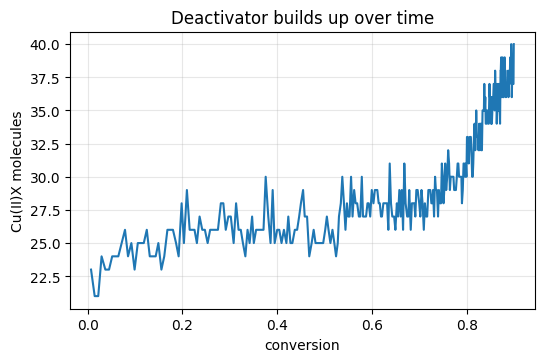

In [4]:
plt.plot(H["x"], H["Cu2"]); plt.xlabel("conversion"); plt.ylabel("Cu(II)X molecules")
plt.title("Deactivator builds up over time"); plt.show()

## Part B · Degradation: running polymerization *backwards* 🔥
Start from a Flory distribution (like Notebook 2) and break chains with two toy reactions:

| reaction | rate | effect |
|---|---|---|
| random scission | `k_s × (number of C–C bonds)` | a chain of length n splits at a random bond |
| end unzipping | `k_dp × (number of chain ends)` | one monomer drops off an end (volatile) |

For random scission alone, theory gives `1/DPn = 1 − (1 − 1/DPn₀)·e^(−k_s t)` (≈ `1/DPn₀ + k_s t` at early times).

Selecting a **bond** at random means long chains are picked more often. A neat trick for that is *rejection sampling*: pick a random chain, accept it with probability `(n−1)/(n_max−1)`.

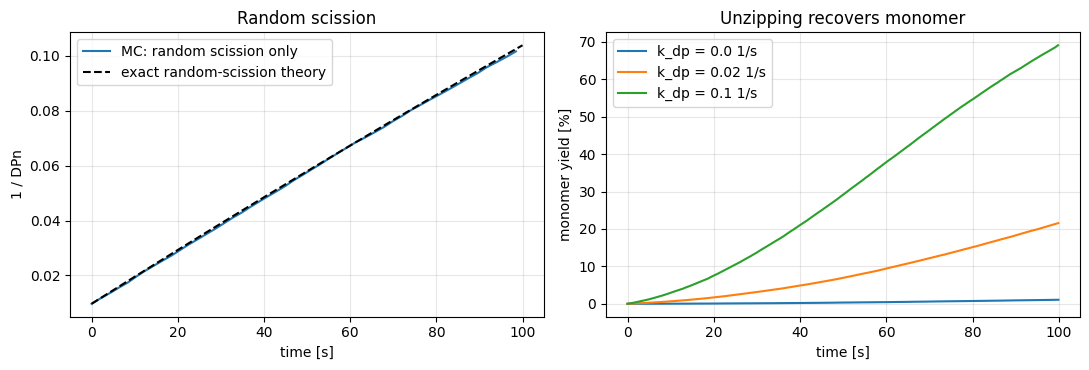

In [5]:
def degrade(N=1000, DPn0=100, ks=1e-3, kdp=0.0, t_max=100.0):
    L = list(np.random.default_rng(0).geometric(1/DPn0, size=N))
    L = [x for x in L if x >= 2]
    units0 = sum(L); bonds = sum(x - 1 for x in L)
    monomer, t, step, nmax = 0, 0.0, 0, max(L)
    hist = {"t": [0.0], "DPn": [units0/len(L)], "mono": [0.0]}   # DPn counts monomer fragments too
    while t < t_max and L:
        R = [ks*bonds, kdp*2*len(L)]
        j = roulette(R)
        if j == 0:                                         # random scission
            while True:                                    # rejection sampling, weight ∝ bonds
                k = random.randrange(len(L))
                if random.random() <= (L[k]-1)/(nmax-1): break
            cut = random.randint(1, L[k]-1)
            a, b = cut, L[k]-cut
            L[k] = a; L.append(b); bonds -= 1
        else:                                              # unzip one monomer from an end
            k = random.randrange(len(L)); L[k] -= 1; monomer += 1; bonds -= 1
        for idx in [k, len(L)-1]:                          # chains of length 1 = volatile monomer
            if idx < len(L) and L[idx] == 1:
                L[idx] = L[-1]; L.pop(); monomer += 1
        t += np.log(1/random.random()) / sum(R); step += 1
        if step % 1000 == 0:
            nmax = max(L)                                  # keep rejection sampling efficient
        if step % 200 == 0:
            hist["t"].append(t); hist["DPn"].append(units0/(len(L) + monomer)); hist["mono"].append(monomer/units0)
    return {k: np.array(v) for k, v in hist.items()}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
H0 = degrade(kdp=0.0)
tt = np.linspace(0, 100, 50)
ax[0].plot(H0["t"], 1/H0["DPn"], label="MC: random scission only")
ax[0].plot(tt, 1 - (1 - 1/H0["DPn"][0])*np.exp(-1e-3*tt), "k--", label="exact random-scission theory")
ax[0].set_xlabel("time [s]"); ax[0].set_ylabel("1 / DPn"); ax[0].legend(); ax[0].set_title("Random scission")
for kdp in [0.0, 0.02, 0.1]:
    Hk = degrade(kdp=kdp)
    ax[1].plot(Hk["t"], 100*Hk["mono"], label=f"k_dp = {kdp} 1/s")
ax[1].set_xlabel("time [s]"); ax[1].set_ylabel("monomer yield [%]"); ax[1].legend(); ax[1].set_title("Unzipping recovers monomer")
plt.tight_layout(); plt.show()

## 🎓 Course recap
| Notebook | Core idea | Data structure |
|---|---|---|
| 1 | `Rnd ≤ P`, counting, roulette wheel, waiting times | – |
| 2 | one chain at a time → MWD | counting vector `D` |
| 3 | extra label per chain (composition) | arrays `D`, `N1` |
| 4 | molecules that react again | pool list |
| 5 | pick-two-and-merge; networks | `Bag`, `DSU` |
| 6–7 | real time from rates | lists of active / dormant / dead chains |

### 🧪 Try it yourself
1. ATRP: lower `kda` by 10×. What happens to Đ? Why?
2. ATRP: start with `nCu2 = 0`. Look at the first few hundred events.
3. Degradation: start from a *narrow* (Poisson) distribution instead of Flory. Does random scission push it toward Đ = 2?

📖 For copolymer ATRP, the full 9-reaction polystyrene pyrolysis model, and many more case studies, see {BOOK}.